# LAB | Micromanage your agents

**Scenario:** you are building an evaluation system for **one specific use case**. Public benchmarks (like HLE in class) don't reflect your client's real questions, so you build **your own dataset**, upload it to LangSmith, run experiments and report what you found.

**How to use this notebook:**
- Cells marked **`# TODO`** are yours to complete. Replace every `...` with your code.
- **Hints** point to the lesson notebook (`02_langsmith(1).ipynb`), where you saw each idea.
- Markdown cells with a bold prompt (e.g. **Document your choice here:**, **Key findings:**) are for your written answers.
- Run the cells **in order**, top to bottom.

| Part | You will… | Concept from class |
|---|---|---|
| 1 | Choose a domain + set up LangSmith | Tracing, projects, regions |
| 2 | Build and upload your own dataset | Datasets: inputs, reference outputs, metadata |
| 3 | Write the target function + evaluators | Target, LLM-as-a-judge (OpenEvals), exact match |
| 4 | Run the experiment and review it in the UI | `client.evaluate()`, experiments, feedback |
| 5 | Analyse results + write `evaluation_summary.md` | Metrics, error analysis |
| Optional 1 | Design a custom evaluator | Judge prompt anatomy (notebook 01) |
| Optional 2 | A/B test models on cost vs performance | Model comparison, cost per correct answer |

In [1]:
%pip install langsmith openai openevals python-dotenv pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Part 1: Setup & document selection (30–45 min)
### Step 1: Choose your domain and documents

Pick a domain where **you** can judge what a good answer looks like. Ideas: customer support FAQ, a company policy, a product catalogue, course material, a legal or compliance text, code review…

Each example needs:
- a clear **input** (question, ticket, task)
- ideally an **expected output** (reference answer, label, summary)
- enough **variety**: easy and hard cases, different categories

 **Hint:** the best datasets include **tricky cases**: questions with no answer in the document, ambiguous wording, multi-step questions. Easy-only datasets give 100% scores and teach you nothing (remember the calibration set in notebook 01, §6).

**Document your choice here:**
- **Domain (2–3 sentences):** A Q&A assistant for the EU AI Act, aimed at business users (e.g. an operations or HR team) who want to know whether an AI use case is allowed and what obligations apply. The assistant answers using only an excerpt of the Act provided as context. The client's real questions are about prohibited practices, risk categories, transparency duties and key dates.
- **Source(s) of my documents:** Regulation (EU) 2024/1689 (Artificial Intelligence Act), official text on EUR-Lex: https://eur-lex.europa.eu/eli/reg/2024/1689/oj
- **One example (input → expected output):** "Can we use AI to detect employees' emotions during video calls?" → "No. Emotion recognition in the workplace is prohibited under Article 5(1)(f), except for medical or safety reasons."
- **What makes a good answer in my domain?** It gives the correct verdict (allowed / prohibited / depends), cites the right article, stays within what the context says, and says clearly when the context doesn't answer the question instead of guessing.

### Step 2: Set up LangSmith

 **Hint:** copy the setup pattern from `02_langsmith(1).ipynb` (Setup: keys and region). Your `.env` needs `LANGSMITH_API_KEY` and `OPENAI_API_KEY`. Check your **region**: `eu.smith.langchain.com` in the browser means EU.

In [2]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)

os.environ["LANGSMITH_TRACING"] = "true"
PROJECT_NAME = "lab-langsmith-eu-ai-act"
os.environ["LANGSMITH_PROJECT"] = PROJECT_NAME
os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"   # EU region (eu.smith.langchain.com)

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from langsmith import Client, traceable
from langsmith.wrappers import wrap_openai
from openai import OpenAI
from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)   # charts and CSVs are saved here

client = Client()
openai_client = wrap_openai(OpenAI())

datasets = list(client.list_datasets())
print(f"Connected. I can see {len(datasets)} datasets.")

Connected. I can see 1 datasets.


## Part 2: Dataset creation (60–90 min)
### Step 3: Extract and structure your examples

Turn your documents into a list of examples. Every example is a dictionary with the **same keys**.

| Field | Goes to | Example |
|---|---|---|
| `question` (+ `context` if RAG-style) | **inputs**: what the model sees | "Can I return a sale item?" |
| `answer` | **outputs**: the reference answer | "Yes, within 14 days, store credit only." |
| `category`, `difficulty`, `source` | **metadata**: for analysis, the model never sees it | "returns", "hard", "policy.pdf p.3" |

 **Hint:** aim for **15–20 examples** (minimum 10). Include at least 2 categories and at least 2 "hard" or "trap" examples.

In [4]:
examples = [
    # ---------- PROHIBITED PRACTICES ----------
    {
        "question": "Can we use AI to detect employees' emotions during video calls?",
        "context": "Article 5(1)(f) (summary): The use of AI systems to infer the emotions of a natural person in the areas of workplace and education institutions is prohibited, except where the AI system is intended to be used for medical or safety reasons.",
        "answer": "No. Emotion recognition in the workplace is prohibited under Article 5(1)(f), unless it is used for medical or safety reasons.",
        "category": "prohibited_practices",
        "difficulty": "easy",
        "source": "AI Act Art. 5(1)(f)",
    },
    {
        "question": "Is it allowed to build a facial recognition database by scraping photos from social media?",
        "context": "Article 5(1)(e) (summary): The placing on the market or use of AI systems that create or expand facial recognition databases through the untargeted scraping of facial images from the internet or CCTV footage is prohibited.",
        "answer": "No. Creating or expanding facial recognition databases through untargeted scraping of facial images from the internet is prohibited under Article 5(1)(e).",
        "category": "prohibited_practices",
        "difficulty": "easy",
        "source": "AI Act Art. 5(1)(e)",
    },
    {
        "question": "Can a company score customers on their social behaviour and use that score to refuse them services in unrelated contexts?",
        "context": "Article 5(1)(c) (summary): AI systems that evaluate or classify people over a period of time based on their social behaviour or personal characteristics are prohibited when the resulting social score leads to detrimental treatment in social contexts unrelated to where the data was collected, or treatment that is unjustified or disproportionate.",
        "answer": "No. This is social scoring leading to detrimental treatment in unrelated contexts, which is prohibited under Article 5(1)(c).",
        "category": "prohibited_practices",
        "difficulty": "medium",
        "source": "AI Act Art. 5(1)(c)",
    },
    {
        "question": "An airline uses a camera system that detects pilot fatigue and stress in the cockpit. Is this banned as workplace emotion recognition?",
        "context": "Article 5(1)(f) (summary): The use of AI systems to infer the emotions of a natural person in the areas of workplace and education institutions is prohibited, except where the AI system is intended to be used for medical or safety reasons.",
        "answer": "No. Even if it counts as emotion recognition at work, Article 5(1)(f) has an exception for systems used for safety reasons, which applies to pilot monitoring.",
        "category": "prohibited_practices",
        "difficulty": "hard",
        "source": "AI Act Art. 5(1)(f)",
    },
    {
        "question": "Can the police use real-time facial recognition in a train station to search for a missing child?",
        "context": "Article 5(1)(h) (summary): The use of real-time remote biometric identification in publicly accessible spaces for law enforcement is prohibited, unless strictly necessary for: (i) the targeted search for specific victims of abduction, trafficking or sexual exploitation, and the search for missing persons; (ii) preventing a specific, substantial and imminent threat to life or a terrorist attack; (iii) locating or identifying suspects of certain serious crimes. Each use requires prior authorisation by a judicial or independent administrative authority (Article 5(3)).",
        "answer": "Yes, as an exception. Real-time remote biometric identification is generally prohibited, but the search for missing persons is one of the allowed exceptions in Article 5(1)(h), subject to prior authorisation.",
        "category": "prohibited_practices",
        "difficulty": "hard",
        "source": "AI Act Art. 5(1)(h), 5(3)",
    },
    # ---------- HIGH-RISK ----------
    {
        "question": "Is an AI tool that screens and ranks job applicants' CVs a high-risk AI system?",
        "context": "Annex III, point 4(a) (summary): AI systems intended to be used for the recruitment or selection of natural persons, in particular to place targeted job advertisements, to analyse and filter job applications, and to evaluate candidates, are high-risk.",
        "answer": "Yes. AI used to analyse and filter job applications and evaluate candidates is high-risk under Annex III, point 4(a).",
        "category": "high_risk",
        "difficulty": "easy",
        "source": "AI Act Annex III 4(a)",
    },
    {
        "question": "Is an AI system that assesses the creditworthiness of individuals high-risk? What if it is only used to detect financial fraud?",
        "context": "Annex III, point 5(b) (summary): AI systems intended to be used to evaluate the creditworthiness of natural persons or establish their credit score are high-risk, with the exception of AI systems used for the purpose of detecting financial fraud.",
        "answer": "Credit scoring of individuals is high-risk under Annex III, point 5(b). A system used only to detect financial fraud is explicitly excluded.",
        "category": "high_risk",
        "difficulty": "medium",
        "source": "AI Act Annex III 5(b)",
    },
    {
        "question": "Our HR tool only checks application forms for missing fields before a human reviews them. It is in an Annex III area. Is it automatically high-risk?",
        "context": "Article 6(3) (summary): An AI system listed in Annex III is not considered high-risk if it does not pose a significant risk of harm, for example if it only performs a narrow procedural task, improves the result of a previously completed human activity, or performs a preparatory task. However, an Annex III system is always high-risk if it performs profiling of natural persons. Article 6(4): a provider who considers that its Annex III system is not high-risk must document that assessment.",
        "answer": "Not automatically. Under Article 6(3) it is not high-risk if it only performs a narrow procedural task and does not profile people. The provider must document this assessment (Article 6(4)).",
        "category": "high_risk",
        "difficulty": "hard",
        "source": "AI Act Art. 6(3), 6(4)",
    },
    # ---------- TRANSPARENCY ----------
    {
        "question": "Do we have to tell customers that they are talking to an AI chatbot?",
        "context": "Article 50(1) (summary): Providers must ensure that AI systems intended to interact directly with natural persons are designed so that those persons are informed that they are interacting with an AI system, unless this is obvious from the circumstances and context of use.",
        "answer": "Yes. Under Article 50(1), people must be informed they are interacting with an AI system, unless it is obvious from the context.",
        "category": "transparency",
        "difficulty": "easy",
        "source": "AI Act Art. 50(1)",
    },
    {
        "question": "We publish clearly satirical AI-generated videos of a famous actor. Do we have to disclose that they are AI-generated?",
        "context": "Article 50(4) (summary): Deployers of an AI system that generates or manipulates image, audio or video content constituting a deep fake must disclose that the content has been artificially generated or manipulated. Where the content is part of an evidently artistic, creative, satirical or fictional work, this obligation is limited to disclosing the existence of such content in an appropriate manner that does not hamper the display or enjoyment of the work.",
        "answer": "Yes, but in a lighter form. Deep fakes must be disclosed under Article 50(4); for evidently satirical work, the disclosure only needs to be made in an appropriate way that does not hamper the enjoyment of the work.",
        "category": "transparency",
        "difficulty": "medium",
        "source": "AI Act Art. 50(4)",
    },
    # ---------- PENALTIES & OBLIGATIONS ----------
    {
        "question": "What is the maximum fine for using a prohibited AI practice?",
        "context": "Article 99(3) (summary): Non-compliance with the prohibited AI practices in Article 5 is subject to fines of up to EUR 35 000 000 or, if the offender is an undertaking, up to 7% of its total worldwide annual turnover for the preceding financial year, whichever is higher.",
        "answer": "Up to EUR 35 million or 7% of total worldwide annual turnover, whichever is higher (Article 99(3)).",
        "category": "penalties_obligations",
        "difficulty": "easy",
        "source": "AI Act Art. 99(3)",
    },
    {
        "question": "We are a small startup (SME). If we break an AI Act prohibition, is our fine also 35 million or 7% of turnover, whichever is higher?",
        "context": "Article 99(3) (summary): Non-compliance with the prohibited AI practices is subject to fines of up to EUR 35 000 000 or up to 7% of total worldwide annual turnover, whichever is higher. Article 99(6) (summary): For SMEs, including start-ups, each fine is up to the percentage or amount referred to, whichever is lower.",
        "answer": "No. For SMEs and start-ups the cap is whichever of the two amounts is lower (Article 99(6)), not whichever is higher.",
        "category": "penalties_obligations",
        "difficulty": "hard",
        "source": "AI Act Art. 99(3), 99(6)",
    },
    {
        "question": "Before an employer starts using a high-risk AI system at the workplace, who must it inform?",
        "context": "Article 26(7) (summary): Before putting into service or using a high-risk AI system at the workplace, deployers who are employers must inform workers' representatives and the affected workers that they will be subject to the use of the high-risk AI system.",
        "answer": "The workers' representatives and the affected workers (Article 26(7)).",
        "category": "penalties_obligations",
        "difficulty": "medium",
        "source": "AI Act Art. 26(7)",
    },
    # ---------- SCOPE & TIMELINE ----------
    {
        "question": "From when do the AI Act's prohibitions apply?",
        "context": "Article 113 (summary): The Regulation entered into force on 1 August 2024 and generally applies from 2 August 2026. However, Chapters I and II (general provisions, including AI literacy, and prohibited AI practices) apply from 2 February 2025, and Chapter V (general-purpose AI models) applies from 2 August 2025.",
        "answer": "From 2 February 2025 (Article 113).",
        "category": "scope_timeline",
        "difficulty": "easy",
        "source": "AI Act Art. 113",
    },
    {
        "question": "When did the obligations for providers of general-purpose AI models start to apply?",
        "context": "Article 113 (summary): The Regulation entered into force on 1 August 2024 and generally applies from 2 August 2026. However, Chapters I and II (general provisions, including AI literacy, and prohibited AI practices) apply from 2 February 2025, and Chapter V (general-purpose AI models) applies from 2 August 2025.",
        "answer": "From 2 August 2025 (Article 113, Chapter V).",
        "category": "scope_timeline",
        "difficulty": "medium",
        "source": "AI Act Art. 113",
    },
    {
        "question": "Does the AI Act apply to me when I use an AI chatbot to plan my private holiday?",
        "context": "Article 2(10) (summary): The Regulation does not apply to obligations of deployers who are natural persons using AI systems in the course of a purely personal non-professional activity.",
        "answer": "No. Purely personal, non-professional use by individuals is outside the scope of the AI Act's deployer obligations (Article 2(10)).",
        "category": "scope_timeline",
        "difficulty": "easy",
        "source": "AI Act Art. 2(10)",
    },
    {
        "question": "Above what amount of training compute is a general-purpose AI model presumed to have systemic risk?",
        "context": "Article 51(2) (summary): A general-purpose AI model is presumed to have high-impact capabilities, and therefore systemic risk, when the cumulative amount of computation used for its training, measured in floating point operations, is greater than 10^25.",
        "answer": "When its cumulative training compute is greater than 10^25 floating point operations (FLOPs) (Article 51(2)).",
        "category": "scope_timeline",
        "difficulty": "medium",
        "source": "AI Act Art. 51(2)",
    },
    # ---------- UNANSWERABLE (TRAPS) ----------
    {
        "question": "Which authority in Germany supervises compliance with the AI Act?",
        "context": "Article 70 (summary): Each Member State must establish or designate at least one notifying authority and at least one market surveillance authority as national competent authorities, and make information on how to contact them publicly available.",
        "answer": "The context does not say. It only states that each Member State must designate at least one notifying authority and one market surveillance authority; it does not name the German authority.",
        "category": "unanswerable",
        "difficulty": "hard",
        "source": "AI Act Art. 70",
    },
    {
        "question": "How much does a conformity assessment for a high-risk AI system cost?",
        "context": "Article 43 (summary): Providers of high-risk AI systems must follow a conformity assessment procedure, either based on internal control or involving a notified body, depending on the type of system, before placing the system on the market.",
        "answer": "The context does not say. It describes the conformity assessment procedures but gives no information on costs.",
        "category": "unanswerable",
        "difficulty": "hard",
        "source": "AI Act Art. 43",
    },
]

In [5]:
# 1. At least 10 examples?
print("Number of examples:", len(examples))

# 2. Same keys everywhere, and no empty question / answer?
first_keys = set(examples[0].keys())
for i, ex in enumerate(examples):
    if set(ex.keys()) != first_keys:
        print(f"Example {i} has different keys")
    if ex["question"].strip() == "" or ex["answer"].strip() == "":
        print(f"Example {i} has an empty question or answer")
print("Key and empty-value check done")

# 3. Examples per category and per difficulty
df_examples = pd.DataFrame(examples)
print(df_examples["category"].value_counts())
print(df_examples["difficulty"].value_counts())

Number of examples: 19
Key and empty-value check done
category
prohibited_practices     5
scope_timeline           4
high_risk                3
penalties_obligations    3
transparency             2
unanswerable             2
Name: count, dtype: int64
difficulty
easy      7
medium    6
hard      6
Name: count, dtype: int64


**My data structure:**
- `question`: a realistic business question about the EU AI Act (input)
- `context`: a short summary of the relevant article(s) of Regulation (EU) 2024/1689, written by me in plain English, not the verbatim legal text (input)
- `answer`: the reference answer: the verdict plus the article it comes from (output)
- `category`: prohibited_practices, high_risk, transparency, penalties_obligations, scope_timeline, unanswerable (metadata)
- `difficulty`: easy / medium / hard. Hard examples are traps: exceptions to a rule (pilot fatigue, missing child), the SME fine rule, a "not automatically high-risk" case, and two questions the context cannot answer (metadata)
- `source`: article reference (metadata)

Changes: I used short summaries instead of full articles to keep inputs short. I left out dates for the high-risk obligations because changes to those were proposed after adoption (Digital Omnibus).

### Step 4: Create the LangSmith dataset

 **Hints (§2 of `02_langsmith(1).ipynb`):**
- Check `client.list_datasets()` first, so re-running the cell doesn't create a duplicate.
- `client.create_dataset(name, description=...)` then `client.create_examples(inputs=[...], outputs=[...], metadata=[...], dataset_id=...)`.
- Put a **version** in the name (e.g. `-v1`). If you change the examples later, create `-v2` instead of editing silently.

In [6]:
DATASET_NAME = "eu-ai-act-qa-v1"
DATASET_DESCRIPTION = "Q&A on the EU AI Act (Regulation 2024/1689) for business users: prohibited practices, high-risk, transparency, penalties, scope/timeline, plus unanswerable trap questions. Each input has a short article summary as context."

# create the dataset only if it doesn't exist yet
existing = [d.name for d in client.list_datasets()]
if DATASET_NAME not in existing:
    dataset = client.create_dataset(DATASET_NAME, description=DATASET_DESCRIPTION)
    client.create_examples(
        inputs   = [{"question": ex["question"], "context": ex["context"]} for ex in examples],
        outputs  = [{"answer": ex["answer"]} for ex in examples],
        metadata = [{"category": ex["category"], "difficulty": ex["difficulty"], "source": ex["source"]} for ex in examples],
        dataset_id = dataset.id,
    )
    print(f"Created '{DATASET_NAME}' with {len(examples)} examples")
else:
    print(f"'{DATASET_NAME}' already exists, skipping upload")

# verify: count the examples stored in LangSmith
stored = list(client.list_examples(dataset_name=DATASET_NAME))
print("Examples in LangSmith:", len(stored))

'eu-ai-act-qa-v1' already exists, skipping upload
Examples in LangSmith: 19


**Go and look:** open **Datasets → your dataset** in LangSmith. Are inputs, reference outputs and metadata all there? Take a **screenshot** for your repo.

** Dataset name + description:**
- Name: `eu-ai-act-qa-v1`
- Description: 19 Q&A examples on the EU AI Act (Regulation 2024/1689) for business users, across 6 categories (prohibited practices, high-risk, transparency, penalties/obligations, scope/timeline, unanswerable). Inputs = question + short article summary as context; output = reference answer with article; metadata = category, difficulty, source.

## Part 3: Evaluation setup (45–60 min)
### Step 5: Target function

The target is **the system under test**: it takes `inputs` from one example and returns `outputs`.

 **Hints (§3 of `02_langsmith(1).ipynb`):**
- Signature: `def target(inputs: dict) -> dict`, returning e.g. `{"answer": "..."}`.
- Add `@traceable` so the whole function (not only the OpenAI call) appears as one trace.
- Set `temperature=0` for controlled randomness (§5 Reproducibility: still not 100% guaranteed).
- **gpt-5 family:** use `max_completion_tokens` instead of `max_tokens`, and `reasoning_effort="none"` for short direct answers.
- **Error handling:** wrap the API call in `try/except` and return `{"answer": "", "error": str(e)}`, so one failure doesn't stop the whole experiment.

In [7]:
MODEL = "gpt-4o-mini"

SYSTEM_PROMPT = '''
You are an assistant that answers business questions about the EU AI Act.
Use ONLY the context provided. Do not use outside knowledge.
Answer in 1-3 sentences: start with a clear verdict (e.g. Yes / No / Not automatically),
then give the reason and the article number from the context.
If the context does not contain the answer, say "The context does not say." and briefly explain what it does cover.
'''

@traceable(name="lab-target")
def target(inputs: dict) -> dict:
    user_message = f"Context:\n{inputs['context']}\n\nQuestion:\n{inputs['question']}"
    try:
        response = openai_client.chat.completions.create(
            model=MODEL,
            temperature=0,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": user_message},
            ],
        )
        return {"answer": response.choices[0].message.content}
    except Exception as e:
        return {"answer": "", "error": str(e)}

In [8]:
for ex in examples[:3]:
    result = target({"question": ex["question"], "context": ex["context"]})
    print("QUESTION: ", ex["question"])
    print("MODEL:    ", result["answer"])
    print("REFERENCE:", ex["answer"])
    print("-" * 60)

QUESTION:  Can we use AI to detect employees' emotions during video calls?
MODEL:     No, the use of AI systems to infer the emotions of a natural person in the workplace is prohibited under Article 5(1)(f), except for medical or safety reasons.
REFERENCE: No. Emotion recognition in the workplace is prohibited under Article 5(1)(f), unless it is used for medical or safety reasons.
------------------------------------------------------------
QUESTION:  Is it allowed to build a facial recognition database by scraping photos from social media?
MODEL:     No, it is not allowed to build a facial recognition database by scraping photos from social media, as this falls under the prohibition of creating or expanding facial recognition databases through untargeted scraping of facial images from the internet. This is outlined in Article 5(1)(e).
REFERENCE: No. Creating or expanding facial recognition databases through untargeted scraping of facial images from the internet is prohibited under Art

### Step 6: Evaluators

 **Hints:**
- Correctness: OpenEvals `CORRECTNESS_PROMPT` + `create_llm_as_judge(...)`, exactly as in §3 of `02_langsmith(1).ipynb`.
- Use a **different (stronger) model as judge** than the model under test.
- Exact match only makes sense when answers are short labels (a letter, a category, a number). For free-text answers, skip it or use a keyword check instead.
- An evaluator function returns a dict like `{"key": "my_metric", "score": True}`.

In [9]:
import re

JUDGE_MODEL = "openai:gpt-5.4-mini"   # stronger than the model under test

# 1. Correctness: LLM-as-a-judge
_correctness_judge = create_llm_as_judge(
    prompt=CORRECTNESS_PROMPT,
    model=JUDGE_MODEL,
    feedback_key="correctness",
)

def correctness_evaluator(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
    return _correctness_judge(
        inputs=inputs,
        outputs=outputs,
        reference_outputs=reference_outputs,
    )

# 2. Rule-based: does the answer cite the same article(s) as the reference?
#    For unanswerable questions: does the answer say "does not say"?
def rule_evaluator(outputs: dict, reference_outputs: dict) -> dict:
    model_answer = outputs["answer"].lower()
    reference = reference_outputs["answer"].lower()

    if "does not say" in reference:
        score = "does not say" in model_answer
    else:
        # find references like "article 5" or "annex iii" in the reference answer
        refs = re.findall(r"article \d+|annex iii", reference)
        # \b = the number must end there, so "article 5" does not match "article 50"
        score = all(re.search(r + r"\b", model_answer) is not None for r in refs)

    return {"key": "cites_correct_article", "score": score}

In [10]:
test_inputs = {"question": examples[0]["question"], "context": examples[0]["context"]}
test_reference = {"answer": examples[0]["answer"]}

good_output = {"answer": "No. Emotion recognition at the workplace is prohibited under Article 5(1)(f), except for medical or safety reasons."}
bad_output  = {"answer": "Yes, this is allowed as long as employees give consent under Article 50."}

print("GOOD:", correctness_evaluator(test_inputs, good_output, test_reference))
print("GOOD:", rule_evaluator(good_output, test_reference))
print("BAD: ", correctness_evaluator(test_inputs, bad_output, test_reference))
print("BAD: ", rule_evaluator(bad_output, test_reference))

GOOD: {'key': 'correctness', 'score': True, 'comment': 'The response correctly answers the question with a clear "No" and accurately reflects the provided context that AI systems used to infer emotions in the workplace are prohibited except for medical or safety reasons. It is complete, factually consistent, and uses appropriate terminology. Thus, the score should be: true.', 'metadata': None}
GOOD: {'key': 'cites_correct_article', 'score': True}
BAD:  {'key': 'correctness', 'score': False, 'comment': 'The response is incorrect. The context states that using AI to infer emotions in the workplace is prohibited, except for medical or safety reasons. The answer instead says it is allowed with employee consent under Article 50, which is not supported by the provided context and directly contradicts the reference output. It also fails to mention the prohibition and the medical/safety exception. Thus, the score should be: false.', 'metadata': None}
BAD:  {'key': 'cites_correct_article', 'sco

**What does "correct" mean in my domain?**
There is one correct verdict per question (allowed / prohibited / not automatically / the context does not say), but many valid wordings. So exact match doesn't work, and I use two evaluators:
- **Correctness (LLM judge, gpt-5.4-mini):** does the answer reach the same verdict and key facts as the reference (e.g. the exception, the date, the fine)? Wording can differ.
- **cites_correct_article (rule-based):** does the answer cite the same article(s) as the reference? For unanswerable questions: does it say "the context does not say" instead of guessing? It's cheap and deterministic, but it only checks the citation, not whether the answer is complete.

## Part 4: Run the evaluation (30–45 min)
### Step 7: Execute the experiment

 **Hint (§3 of `02_langsmith(1).ipynb`):** `client.evaluate(target, data=..., evaluators=[...], experiment_prefix=..., max_concurrency=2)`. Use a prefix that tells you **what** ran, e.g. `"gpt-4o-mini-promptv1"`.

In [11]:
results = client.evaluate(
    target,
    data=DATASET_NAME,
    evaluators=[correctness_evaluator, rule_evaluator],
    experiment_prefix="gpt-4o-mini-promptv1-rulefix",
    max_concurrency=2,
)
print(results)

/opt/anaconda3/envs/bootcamp-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


View the evaluation results for experiment: 'gpt-4o-mini-promptv1-rulefix-9edb81ae' at:
https://eu.smith.langchain.com/o/6a443e3e-a646-46d2-8426-409f0215ab77/datasets/516fe224-9104-44fa-99fd-fd6dfd3bf85a/compare?selectedSessions=eefea85a-9afb-4420-b164-c0021d1d4f89




19it [00:15,  1.25it/s]

<ExperimentResults gpt-4o-mini-promptv1-rulefix-9edb81ae>


In [12]:
df = results.to_pandas()
print(df.columns.tolist())    # find the inputs.*, outputs.*, reference.*, feedback.* columns

# check that every example was processed
print("Rows in results:", len(df), "| examples in dataset:", len(examples))

# check for empty answers (= API errors)
empty = df[df["outputs.answer"] == ""]
print("Empty answers:", len(empty))

df.to_csv(OUT / "results_main.csv", index=False)

['inputs.context', 'inputs.question', 'outputs.answer', 'error', 'reference.answer', 'feedback.correctness', 'feedback.cites_correct_article', 'execution_time', 'example_id', 'id']
Rows in results: 19 | examples in dataset: 19
Empty answers: 0


### Step 8: Review the results in the LangSmith UI

**Go and look:** click the experiment link printed above.
- Open 2–3 **failed** examples and read the judge's reasoning (`comment`).
- Do the LLM judge and your rule-based evaluator **agree**? Look at the rows where they don't.
- Take **screenshots** (experiment table + one trace) for your repo.

** First observations + experiment link:**
- Final experiment (`gpt-4o-mini-promptv1-rulefix-9edb81ae`): https://eu.smith.langchain.com/o/6a443e3e-a646-46d2-8426-409f0215ab77/datasets/516fe224-9104-44fa-99fd-fd6dfd3bf85a/compare?selectedSessions=eefea85a-9afb-4420-b164-c0021d1d4f89
- All 19 examples were processed, with no errors or empty answers. In the final run both evaluators scored 19/19, so the evaluators agree on every row.
- I ran the experiment three times: 100% → 95% → 100% correctness. In the middle run one example failed (HR form-checking tool, Article 6(3)): the verdict was right, but the answer left out the Article 6(4) duty to document the assessment. In that run the evaluators disagreed: the article check passed, the judge failed it. The same question passed in the other two runs, so results are not fully reproducible even at temperature 0.
- I read the judge comments on the hard cases (pilot fatigue, missing child, SME fine, unanswerable questions). The reasoning checked the verdict and the exception, not just the wording.
- My evaluator test caught a bug in the first rule-based check ("Article 50" matched "Article 5"). I fixed it with a word-boundary match and reran.

## Part 5: Analysis & reporting (45–60 min)
### Step 9: Analyse results

In [13]:
feedback_cols = [c for c in df.columns if c.startswith("feedback.")]

for col in feedback_cols:
    scores = df[col].astype(float)
    print(f"{col}: pass rate = {scores.mean():.0%} | n = {len(scores)} | failed = {int((scores == 0).sum())}")

feedback.correctness: pass rate = 100% | n = 19 | failed = 0
feedback.cites_correct_article: pass rate = 100% | n = 19 | failed = 0


                       feedback.correctness  feedback.cites_correct_article
category                                                                   
high_risk                               1.0                             1.0
penalties_obligations                   1.0                             1.0
prohibited_practices                    1.0                             1.0
scope_timeline                          1.0                             1.0
transparency                            1.0                             1.0
unanswerable                            1.0                             1.0
            feedback.correctness  feedback.cites_correct_article
difficulty                                                      
easy                         1.0                             1.0
hard                         1.0                             1.0
medium                       1.0                             1.0


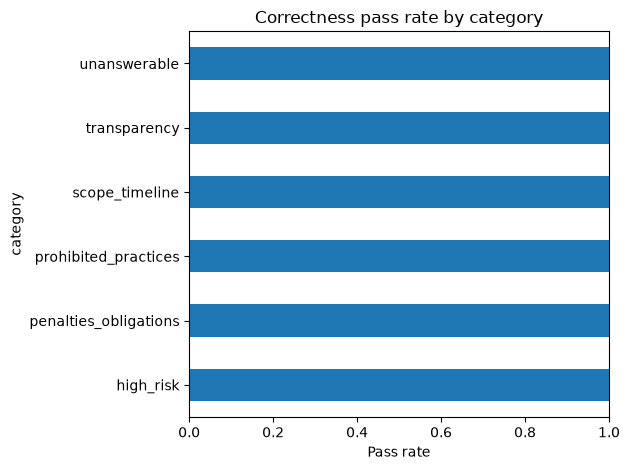

In [14]:
# The results DataFrame has no metadata, so join it from the dataset:
meta = pd.DataFrame([
    {"example_id": str(e.id), **(e.metadata or {})}
    for e in client.list_examples(dataset_name=DATASET_NAME)
])
df["example_id"] = df["example_id"].astype(str)
df = df.merge(meta, on="example_id", how="left")

# pass rate by category and by difficulty
by_category = df.groupby("category")[feedback_cols].mean()
by_difficulty = df.groupby("difficulty")[feedback_cols].mean()
print(by_category.round(2))
print(by_difficulty.round(2))

# bar chart: correctness by category
by_category["feedback.correctness"].sort_values().plot(kind="barh")
plt.title("Correctness pass rate by category")
plt.xlabel("Pass rate")
plt.xlim(0, 1)
plt.tight_layout()
plt.savefig(OUT / "pass_rate_by_category.png", dpi=120)
plt.show()

In [ ]:
# 1. Show every failed example with the judge comment
comments = {}
for r in results:
    ex_id = str(r["example"].id)
    for ev in r["evaluation_results"]["results"]:
        if ev.key == "correctness":
            comments[ex_id] = ev.comment
df["judge_comment"] = df["example_id"].map(comments)

failed = df[(df["feedback.correctness"] == False) | (df["feedback.cites_correct_article"] == False)]
if len(failed) == 0:
    print("No failed examples in this run.")
for _, row in failed.iterrows():
    print("CATEGORY: ", row["category"], "|", row["difficulty"])
    print("QUESTION: ", row["inputs.question"])
    print("MODEL:    ", row["outputs.answer"])
    print("REFERENCE:", row["reference.answer"])
    print("CORRECT:  ", row["feedback.correctness"], "| ARTICLE:", row["feedback.cites_correct_article"])
    print("JUDGE:    ", row["judge_comment"])
    print("-" * 70)

# 2. Failure type, labelled by hand after reading each failed example.
#    This one failed in my second run (95%); it passed in the final run.
failure_types = {
    "Our HR tool only checks application forms for missing fields before a human reviews them. It is in an Annex III area. Is it automatically high-risk?":
        "incomplete (borderline: strict reference)",
}
df["failure_type"] = None
df.loc[failed.index, "failure_type"] = failed["inputs.question"].map(failure_types)
print(df[df["failure_type"].notna()][["category", "difficulty", "failure_type"]])

df.to_csv(OUT / "results_analysed.csv", index=False)

**Key findings:**
1. **Overall pass rate (final run):** correctness (LLM judge) 100% (19/19); cites_correct_article 100% (19/19). Across three runs, correctness was 100%, 95% and 100%.
2. **Easiest and hardest category:** in the final run every category and difficulty level scored 100%. The only category that ever failed was high_risk (2/3 in the middle run, on a hard example).
3. **Biggest failure pattern:** incomplete answers on multi-part rules, and only some of the time. Example: for the HR form-checking tool, the model once applied the Article 6(3) exception correctly but left out the Article 6(4) documentation duty. The bigger issue is the dataset itself: each context already states the rule and its exception, so the model mostly has to read it back.
4. **Judge mistake or bad reference?** Borderline. In the failed run the judge followed the reference correctly, but the question didn't explicitly ask about documentation, so a human might accept the answer. Separately, my rule-based evaluator had a substring bug, which I fixed.

 **Remember (W7/D5 statistics):** with 15–20 examples, every score is an **estimate**. One extra failure moves the pass rate by 5–7 points. The difference between my runs (95% vs 100%) came from one single example, so it's within normal variation.

### Step 10: `evaluation_summary.md`

**One short paragraph** (plus optional bullets/table): what you evaluated, main metrics, biggest failure pattern, limitations, one recommendation. Not a long report.

In [ ]:
summary = '''# Evaluation summary

I evaluated gpt-4o-mini (temperature 0) as a Q&A assistant for the EU AI Act, using my own dataset `eu-ai-act-qa-v1`: 19 business questions across 6 categories (prohibited practices, high-risk, transparency, penalties/obligations, scope/timeline, unanswerable), with 6 "hard" trap cases (exceptions, the SME fine rule, and questions the context cannot answer). Each input includes a short summary of the relevant article as context. Two evaluators were used: an LLM judge (gpt-5.4-mini, OpenEvals correctness prompt) and a rule-based check that the answer cites the same article as the reference. In the final run the model scored 100% on both (19/19). Across three runs correctness was 100%, 95% and 100%: in one run the model gave an incomplete answer on a multi-part rule (for an HR form-checking tool it applied the Article 6(3) exception but omitted the Article 6(4) duty to document the assessment), and the same question passed in the other runs. Limitations: 19 examples is small (one failure = about 5 points), the context summaries already contain most of the answer so the dataset is too easy to separate good from great, and the rule-based check verifies citations, not completeness. Testing also caught a substring bug in my rule-based evaluator, which I fixed before the final runs. **Recommendation:** build a `-v2` with more multi-part and borderline questions (where the context is close but not sufficient), and run each experiment more than once before comparing results.

| Metric | Final run | Range over 3 runs |
|---|---|---|
| Correctness (LLM judge) | 100% (19/19) | 95–100% |
| Cites correct article (rule-based) | 100% (19/19) | 100% |

LangSmith experiment (final run): https://eu.smith.langchain.com/o/6a443e3e-a646-46d2-8426-409f0215ab77/datasets/516fe224-9104-44fa-99fd-fd6dfd3bf85a/compare?selectedSessions=eefea85a-9afb-4420-b164-c0021d1d4f89
'''
Path("evaluation_summary.md").write_text(summary, encoding="utf-8")

---
## Optional Part 1: Custom evaluator (60–90 min)
### Step 11: Design it

Pick **one** dimension beyond correctness that matters for your domain: tone, completeness, groundedness in the context, safety / policy compliance, format…

 **Hints:**
- Use the 4-part judge prompt anatomy from notebook 01, §3: task, what you're given, criteria, reasoning steps + output format.
- Your prompt's `{variables}` must match the keyword arguments you pass (`inputs`, `outputs`, `reference_outputs`, or your own like `context`).
- Prebuilt prompts you can adapt: `RAG_GROUNDEDNESS_PROMPT`, `ANSWER_RELEVANCE_PROMPT`, `CONCISENESS_PROMPT`, `TOXICITY_PROMPT` (`print()` one to see how it's written).
- For a 1–5 scale instead of True/False: `create_llm_as_judge(..., continuous=True)` gives a 0–1 score, or `choices=[1, 2, 3, 4, 5]`.

In [17]:
CUSTOM_PROMPT = '''
TODO: your judge prompt with {inputs}, {outputs} (and {reference_outputs} if needed)
'''

custom_judge = ...

def custom_evaluator(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
    ...

# TODO: test on 2-3 hand-made cases (one good, one bad, one borderline)
...

Ellipsis

### Step 12: Run it next to correctness

In [18]:
# TODO: new experiment with correctness + custom evaluator, then compare the two scores per example
results_custom = ...
...
# Which examples are CORRECT but score badly on your custom dimension (or the other way round)?
...

Ellipsis

### Step 13:  Document your custom evaluator
- What it measures and why it matters in my domain:
- Scoring scale and criteria:
- Where it disagreed with correctness, and what that revealed:

---
## Optional Part 2: Cost & performance (60–90 min)
### Step 14: A/B comparison

 **Hints (§4 of `02_langsmith(1).ipynb`):**
- Same dataset, same evaluators, **only one thing changes** (the model, or the temperature, or the prompt).
- To get token usage, also return it from the target: `{"answer": ..., "prompt_tokens": r.usage.prompt_tokens, "completion_tokens": r.usage.completion_tokens}`.
- Latency: look for an `execution_time` column in `results.to_pandas()`.
- Fill `PRICES` from the **OpenAI pricing page** (USD per 1M tokens). Write down the date you checked it.

In [19]:
CONFIGS = {
    # experiment name: model
    "config-a": "gpt-4o-mini",
    "config-b": ...,
    # "config-c": ...,
}

PRICES = {   # USD per 1M tokens, from the OpenAI pricing page (checked on: ...)
    "gpt-4o-mini": {"input": ..., "output": ...},
    # ...
}

def make_target(model):
    @traceable(name=f"lab-target-{model}")
    def _target(inputs: dict) -> dict:
        # TODO: same as your target, but with `model` and token usage in the returned dict
        ...
    return _target

# TODO: run one experiment per config and keep the results
ab_results = {}
...

Ellipsis

### Step 15: Cost vs performance

In [20]:
# TODO: one row per config: pass rate, avg latency, total cost, cost per example, cost per CORRECT answer
# cost = prompt_tokens / 1e6 * price_in + completion_tokens / 1e6 * price_out
...
# TODO: scatter plot: x = cost per example, y = pass rate, one labelled point per config
...
plt.savefig(OUT / "cost_vs_performance.png", dpi=120)
plt.show()

<Figure size 640x480 with 0 Axes>

 **Before you recommend, think:**
- Is the gap between models bigger than **one or two examples**? With ~20 examples it may be luck (W7/D5).
- Which pass rate is **good enough** for this use case? A cheaper model that meets that bar wins.

### Step 16: `optimization_summary.md`

In [21]:
# TODO: one short paragraph: best cost/performance trade-off, and when you would pick each config
opt = '''# Optimization summary

TODO: best trade-off + when to pick each configuration.

| Config | Model | Pass rate | Cost / correct answer | Avg latency |
|---|---|---|---|---|
| ... | ... | ... | ... | ... |
'''
Path("optimization_summary.md").write_text(opt, encoding="utf-8")

204

---
## Reflection (optional, recommended)
1. What surprised you when you read the failed traces?
2. Did you trust your LLM judge? How did you check it?
3. What would you change in your dataset for a `-v2`?

## Submission checklist
- [ ] GitHub repo with **only** this lab, and a `README.md` (domain + dataset, approach, how to run, LangSmith links, file map)
- [ ] `lab_proof.md` as the **entry point**: code/workflow, one run with its input, the evidence it produced (trace / screenshot), the final output, and one failure or limitation you hit
- [ ] `evaluation_summary.md` at the repo root (one paragraph + optional table)
- [ ] (Optional) `optimization_summary.md` at the repo root
- [ ] Notebook runs top to bottom without errors; descriptive file names (no `lab.ipynb`, `final_v2.py`)
- [ ] `outputs/`: results CSV(s), charts, and LangSmith screenshots (dataset, experiment, one trace)
- [ ] **No API keys** in the repo: `.env` is in `.gitignore`